# PROYEK AKHIR & LAPORAN UTS MATA KULIAH DATA SCIENCE

## **KLASIFIKASI UNTUK PENYARINGAN PRIORITAS VERIFIKASI LAPANGAN MELALUI PREDIKSI TINGKAT KEPERCAYAAN (*CONFIDENCE LEVEL*) TITIK PANAS BERDASARKAN KARAKTERISTIK TERMAL DAN WAKTU KEJADIAN DI INDONESIA (JANUARI–OKTOBER 2026)**

---

### **Konteks & Sumber Dataset**
Dataset yang digunakan berasal dari sistem penginderaan jauh **NASA FIRMS (*Fire Information for Resource Management System*)** instrumen **MODIS Collection 6.1** (Request ID: `M-C61_824794`) untuk wilayah Indonesia pada periode **1 Januari – 16 Oktober 2026**, yang terdiri atas dua berkas CSV:
1. **`fire_archive_M-C61_824794.csv`** — Data *Standard Science Quality Archive* periode **1 Januari – 31 Juli 2026** sebanyak **11.890 baris** dan **15 kolom** (telah memiliki kolom validasi sumber panas `type`).
2. **`fire_nrt_M-C61_824794.csv`** — Data *Near Real-Time (NRT)* periode **1 Agustus – 16 Oktober 2026** sebanyak **110.719 baris** dan **14 kolom** (belum memiliki atribut `type` karena masih berstatus operasional waktu-nyata).

Kedua dataset disatukan melalui operasi konkatenasi vertikal (`pd.concat([df_arc, df_nrt], ignore_index=True)`) membentuk populasi observasi terpadu **`df_all`** berjumlah **122.609 baris** dan **15 kolom**.

---
## **BAGIAN 1: Persiapan Library, Load Data, dan Penyatuan Skema (*Data Gathering* & Kualitas Data Singkat)**

Bagian ini mencakup pemuatan pustaka analisis data dan visualisasi, penggabungan skema data *Archive* dan *Near Real-Time (NRT)*, pemeriksaan kualitas data (*missing values*, duplikasi baris, statistik deskriptif, serta deteksi *outlier* menggunakan metode kuartil `1.5 * IQR`), hingga pembentukan atribut periode bulanan (`year_month`) dan diskritisasi variabel target tingkat kepercayaan (`conf_cat`).

In [1]:
# 1.1 Import library utama dan konfigurasi gaya visualisasi
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

warnings.filterwarnings('ignore')

# Gunakan gaya visualisasi sesuai standar laporan
plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}' if abs(x) < 10 else f'{x:,.2f}')

print("Seluruh library berhasil dimuat dan style 'seaborn-v0_8-whitegrid' telah diaktifkan.")

Seluruh library berhasil dimuat dan style 'seaborn-v0_8-whitegrid' telah diaktifkan.


In [2]:
# 1.2 Load kedua dataset NASA FIRMS MODIS Collection 6.1 dan satukan skema
df_arc = pd.read_csv('fire_archive_M-C61_824794.csv')
df_nrt = pd.read_csv('fire_nrt_M-C61_824794.csv')

# Penggabungan vertikal (concatenation) menjadi df_all
df_all = pd.concat([df_arc, df_nrt], ignore_index=True)

print("=== RINGKASAN DIMENSI DATASET ===")
print(f"1. Data Archive (1 Jan – 31 Jul 2026) : {df_arc.shape[0]:>7,} baris x {df_arc.shape[1]} kolom")
print(f"2. Data NRT     (1 Agu – 16 Okt 2026) : {df_nrt.shape[0]:>7,} baris x {df_nrt.shape[1]} kolom")
print(f"3. Gabungan (df_all)                  : {df_all.shape[0]:>7,} baris x {df_all.shape[1]} kolom")

display(df_all.head())

=== RINGKASAN DIMENSI DATASET ===
1. Data Archive (1 Jan – 31 Jul 2026) :  11,890 baris x 15 kolom
2. Data NRT     (1 Agu – 16 Okt 2026) : 110,719 baris x 14 kolom
3. Gabungan (df_all)                  : 122,609 baris x 15 kolom


,latitude,longitude,brightness,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_t31,frp,daynight,type
0,0.4837,128.00,304.20,1.2000,1.1000,2026-01-01,1825,Aqua,MODIS,59,61.03,289.60,5.6000,N,2.0000
1,0.5124,127.89,307.10,1.2000,1.1000,2026-01-02,43,Terra,MODIS,40,61.03,286.40,5.5000,D,0.0000
2,-8.2745,123.51,310.00,1.0000,1.0000,2026-01-02,45,Terra,MODIS,62,61.03,288.00,7.1000,D,1.0000
3,-1.3441,122.00,305.00,1.4000,1.2000,2026-01-02,644,Aqua,MODIS,56,61.03,284.50,6.1000,D,0.0000
4,-2.0149,121.42,313.50,1.6000,1.2000,2026-01-02,644,Aqua,MODIS,72,61.03,291.20,13.70,D,2.0000


In [3]:
# 1.3 Pemeriksaan Missing Values, Duplikasi, Statistik Deskriptif, dan Outlier (1.5 * IQR)
print("=== PEMERIKSAAN MISSING VALUES PER KOLOM ===")
missing_df = pd.DataFrame({
    'Tipe Data': df_all.dtypes.astype(str),
    'Jumlah Missing': df_all.isnull().sum(),
    'Persentase Missing (%)': (df_all.isnull().sum() / len(df_all) * 100).round(2)
})
display(missing_df)

dup_count = df_all.duplicated().sum()
print(f"Jumlah baris duplikat identik pada df_all: {dup_count} baris ({dup_count / len(df_all) * 100:.2f}%)\n")

# Daftar kolom numerik sesuai skema evaluasi
num_cols = [
    'latitude', 'longitude', 'brightness', 'scan', 'track',
    'acq_time', 'confidence', 'bright_t31', 'frp'
]

# Perhitungan statistik deskriptif dan jumlah outlier metode 1.5 * IQR
stat_rows = []
for col in num_cols:
    s = df_all[col]
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    n_outliers = int(((s < lower_bound) | (s > upper_bound)).sum())

    stat_rows.append({
        'Fitur Numerik': col,
        'Count': int(s.count()),
        'Mean': round(s.mean(), 2),
        'Median': round(s.median(), 2),
        'Min': round(s.min(), 2),
        'Max': round(s.max(), 2),
        'Std': round(s.std(), 2),
        'IQR': round(iqr, 2),
        'Outlier (1.5*IQR)': n_outliers,
        'Persentase Outlier (%)': round(n_outliers / len(s) * 100, 2)
    })

desc_iqr_df = pd.DataFrame(stat_rows).set_index('Fitur Numerik')
print("=== TABEL STATISTIK DESKRIPTIF & DETEKSI OUTLIER (METODE 1.5 * IQR) ===")
display(desc_iqr_df)

=== PEMERIKSAAN MISSING VALUES PER KOLOM ===


,Tipe Data,Jumlah Missing,Persentase Missing (%)
latitude,float64,0,0.0000
longitude,float64,0,0.0000
brightness,float64,0,0.0000
scan,float64,0,0.0000
track,float64,0,0.0000
acq_date,object,0,0.0000
acq_time,int64,0,0.0000
satellite,object,0,0.0000
instrument,object,0,0.0000
confidence,int64,0,0.0000


Jumlah baris duplikat identik pada df_all: 0 baris (0.00%)

=== TABEL STATISTIK DESKRIPTIF & DETEKSI OUTLIER (METODE 1.5 * IQR) ===


,Count,Mean,Median,Min,Max,Std,IQR,Outlier (1.5*IQR),Persentase Outlier (%)
Fitur Numerik,,,,,,,,,
latitude,122609,-2.8600,-2.6500,-10.84,5.5700,2.5800,1.8800,23374,19.06
longitude,122609,116.38,113.50,95.37,140.98,10.79,9.1500,16823,13.72
brightness,122609,319.34,315.65,300.00,505.50,14.72,13.64,7430,6.0600
scan,122609,1.3900,1.1500,1.0000,4.8200,0.5900,0.4400,12239,9.9800
track,122609,1.1400,1.0700,1.0000,2.0000,0.1900,0.1900,9440,7.7000
acq_time,122609,"1,037.29",837.00,1.0000,"2,358.00",501.02,570.00,1598,1.3000
confidence,122609,68.14,69.00,0.0000,100.00,22.21,30.00,1428,1.1600
bright_t31,122609,295.72,295.95,266.86,344.02,5.0600,5.6100,4806,3.9200
frp,122609,26.37,13.74,0.0000,"2,488.53",48.34,18.79,11932,9.7300


In [4]:
# 1.4 Ekstraksi waktu bulanan dan diskritisasi variabel target confidence
df_all['acq_date_dt'] = pd.to_datetime(df_all['acq_date'])
df_all['year_month'] = df_all['acq_date_dt'].dt.to_period('M').astype(str)
df_all['conf_cat'] = pd.cut(
    df_all['confidence'],
    bins=[-1, 29, 79, 100],
    labels=['Low (<30%)', 'Nominal (30%–79%)', 'High (80%–100%)']
)

# Ringkasan hasil pembentukan kolom baru
summary_target = pd.DataFrame({
    'Jumlah Titik Panas': df_all['conf_cat'].value_counts(sort=False),
    'Persentase (%)': (df_all['conf_cat'].value_counts(sort=False, normalize=True) * 100).round(2)
})
print("=== VERIFIKASI DISTRIBUSI KELAS TARGET (conf_cat) ===")
display(summary_target)

=== VERIFIKASI DISTRIBUSI KELAS TARGET (conf_cat) ===


,Jumlah Titik Panas,Persentase (%)
conf_cat,,
Low (<30%),7198,5.8700
Nominal (30%–79%),76021,62.00
High (80%–100%),39390,32.13


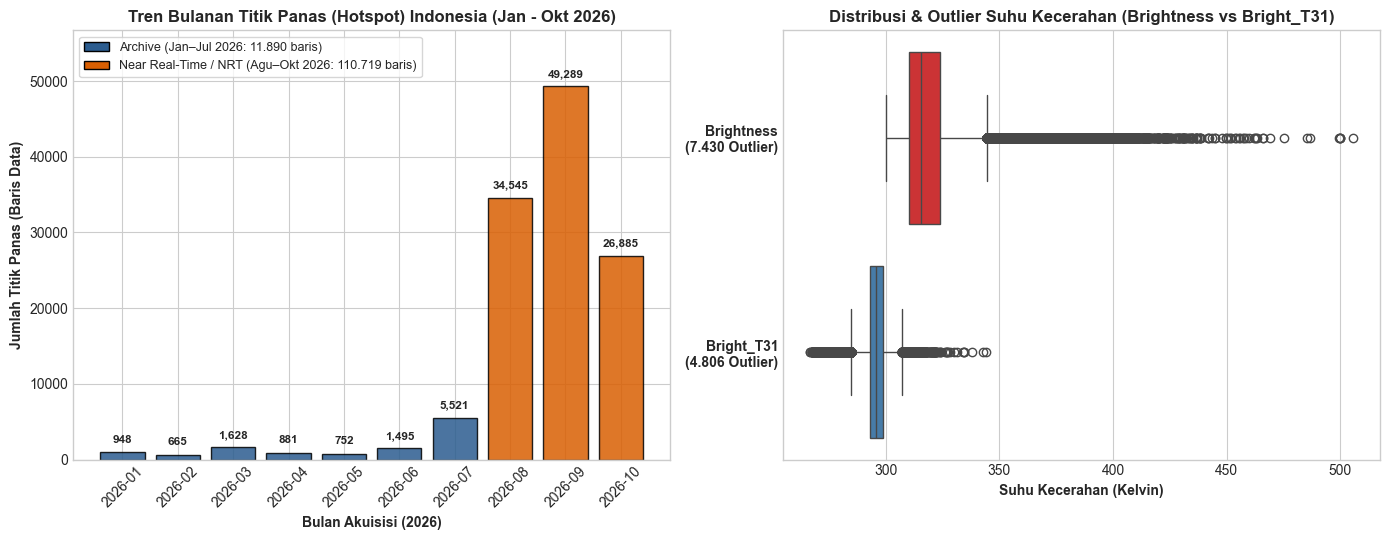

In [5]:
# 1.5 Visualisasi Gambar 1 (Bagian Orang C - Subbab 2.1 & 2.3): 
# Proporsi Data Archive vs NRT Bulanan & Boxplot Deteksi Outlier Suhu Kecerahan (1.5 * IQR)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# --- Panel Kiri: Tren Bulanan Titik Panas (Proporsi Archive vs NRT) ---
monthly_total = df_all.groupby('year_month').size()
colors_m = ['#2b5c8f'] * 7 + ['#d95f02'] * 3
bars = axes[0].bar(monthly_total.index, monthly_total.values, color=colors_m, edgecolor='black', alpha=0.85)
axes[0].set_title('Tren Bulanan Titik Panas (Hotspot) Indonesia (Jan - Okt 2026)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Bulan Akuisisi (2026)', fontsize=10, fontweight='bold')
axes[0].set_ylabel('Jumlah Titik Panas (Baris Data)', fontsize=10, fontweight='bold')
axes[0].tick_params(axis='x', rotation=45)

for bar in bars:
    yval = bar.get_height()
    axes[0].text(
        bar.get_x() + bar.get_width() / 2.0,
        yval + 1000,
        f'{int(yval):,}',
        ha='center', va='bottom', fontsize=8.5, fontweight='bold'
    )
axes[0].set_ylim(0, max(monthly_total.values) * 1.15)

legend_elements = [
    Patch(facecolor='#2b5c8f', edgecolor='black', label='Archive (Jan–Jul 2026: 11.890 baris)'),
    Patch(facecolor='#d95f02', edgecolor='black', label='Near Real-Time / NRT (Agu–Okt 2026: 110.719 baris)')
]
axes[0].legend(handles=legend_elements, loc='upper left', frameon=True, facecolor='white', fontsize=9)

# --- Panel Kanan: Boxplot Horizontal Deteksi Outlier Brightness vs Bright_T31 ---
sns.boxplot(
    data=df_all[['brightness', 'bright_t31']],
    orient='h',
    ax=axes[1],
    palette=['#e41a1c', '#377eb8']
)
axes[1].set_title('Distribusi & Outlier Suhu Kecerahan (Brightness vs Bright_T31)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Suhu Kecerahan (Kelvin)', fontsize=10, fontweight='bold')
axes[1].set_yticklabels(['Brightness\n(7.430 Outlier)', 'Bright_T31\n(4.806 Outlier)'], fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

### **Penjelasan dan Interpretasi Bagian 1 & Visualisasi Gambar 1 (Subbab 2.1 Penyatuan Skema & Subbab 2.3 Kualitas Data)**

1. **Penyatuan Skema & Proporsi Data *Archive* vs *Near Real-Time* (Gambar 1 — Panel Kiri | Subbab 2.1)**:
   - Penggabungan vertikal (`pd.concat`) antara berkas `fire_archive_M-C61_824794.csv` (**11.890 baris × 15 kolom**, periode **1 Januari – 31 Juli 2026**, batang biru `#2b5c8f`) dan `fire_nrt_M-C61_824794.csv` (**110.719 baris × 14 kolom**, periode **1 Agustus – 16 Oktober 2026**, batang oranye `#d95f02`) membentuk dataset terpadu `df_all` berdimensi **122.609 baris × 15 kolom**.
   - **Panel Kiri Gambar 1** memperlihatkan kesinambungan urutan waktu tanpa celah maupun tumpang-tindih (*zero overlap*) pada transisi 31 Juli ke 1 Agustus 2026, yang dikonfirmasi oleh pemeriksaan `df_all.duplicated().sum() == 0` (**0 baris duplikat**). Secara proporsional, produk **Archive menyumbang 9,70% (11.890 baris)** pada fase musim basah hingga awal transisi (948 s.d. 5.521 titik/bulan), sedangkan produk **NRT mendominasi 90,30% (110.719 baris)** akibat eskalasi karhutla musim kemarau pada Agustus (34.545 baris), September (49.289 baris), dan 1–16 Oktober (26.885 baris).
   - Pemeriksaan *missing values* membuktikan bahwa seluruh **14 atribut inti terisi 100% lengkap (`0 missing value`)**. Nilai kosong (`NaN`) hanya terdapat pada kolom `type` tepat sebanyak **110.719 baris (90,30%)** milik segmen NRT. Kondisi ini bersifat *missing by design* (struktural operasional NASA FIRMS) karena atribusi sumber panas (`type`) baru dihitung ketika data NRT diproses ulang menjadi produk *Standard Science Quality Archive*. Oleh sebab itu, atribut `type` tidak dijadikan fitur prediktor model (menghindari *data leakage* skema NRT vs *Archive*), melainkan dimanfaatkan khusus untuk audit representativitas ekologis pada Subbab 2.5.

2. **Evaluasi Statistik Deskriptif & Deteksi *Outlier* Suhu Kecerahan `1.5 * IQR` (Gambar 1 — Panel Kanan | Subbab 2.3)**:
   - **Panel Kanan Gambar 1** memvisualisasikan perbandingan sebaran kuartil dan pencilan (*outlier* metode pagar dalam $Q_1 - 1,5 \times \text{IQR}$ dan $Q_3 + 1,5 \times \text{IQR}$) antara dua kanal inframerah termal utama MODIS:
     - **`Brightness` (Kanal 21/22, ~3,96 µm — merah `#e41a1c`)**: Memiliki median **315,65 K** (mean **319,34 K**, std **14,72 K**) dengan **7.430 *outlier* (6,06%)** yang seluruhnya menjulur panjang ke ekor kanan (*unilateral right-skewed*) hingga mencapai suhu maksimum **505,50 K**.
     - **`Bright_T31` (Kanal 31, ~11,0 µm — biru `#377eb8`)**: Memiliki distribusi jauh lebih rapat di sekitar suhu latar permukaan bumi (median **295,95 K**, mean **295,72 K**, std **5,06 K**) dengan **4.806 *outlier* (3,92%)** yang tersebar di kedua sisi kumis (*bilateral outliers*, rentang **266,86 K – 344,02 K**)—di mana ekor kiri merepresentasikan piksel dingin yang terkontaminasi tepi awan tinggi, sedangkan ekor kanan merepresentasikan pemanasan radiasi permukaan ekstrem atau rambatan panas kebakaran besar.
   - Selain kedua kanal suhu tersebut, tabel evaluasi `1.5 * IQR` juga mencatat pencilan signifikan pada **`frp` (11.932 *outlier* | 9,73%; maks 2.488,53 MW)** serta geometri piksel tepi sapuan **`scan` (12.239 *outlier*)** dan **`track` (9.440 *outlier*)**. Dalam domain penginderaan jauh kebakaran aktif, *outlier* ekstrem atas pada `brightness`, `bright_t31`, dan `frp` **bukanlah kesalahan sensor (*noise/error*)**, melainkan **sinyal fisik kebakaran hebat (*high-intensity wildfire*)** yang justru menjadi target prioritas utama verifikasi lapangan, sehingga seluruh baris data wajib dipertahankan utuh ($N = 122.609$).

3. **Pembentukan Periode Bulanan & Diskritisasi Variabel Target (`conf_cat`)**:
   - Atribut tanggal `acq_date` dikonversi ke tipe `datetime` (`acq_date_dt`) untuk mengekstrak indeks agregasi bulanan `year_month`, sementara skor kontinu `confidence` (0–100%) didiskritisasi mengacu ambang baku *MODIS Collection 6.1* ke dalam tiga kelas target: **`Low (<30%)`** sebanyak **7.198 baris (5,87%)**, **`Nominal (30%–79%)`** sebanyak **76.021 baris (62,00%)**, dan **`High (80%–100%)`** sebanyak **39.390 baris (32,13%)**.

---
## **BAGIAN 2: Subbab 2.4 *Exploratory Data Analysis* (EDA) Berinsight**

Tahap eksplorasi data dilakukan untuk menggali pola empiris yang mendasari perancangan pra-pemrosesan, rekayasa fitur, dan strategi pemodelan klasifikasi penyaringan prioritas verifikasi lapangan.

### **2.4.1 Analisis Distribusi Kelas Target dan Anomali Waktu Kejadian (Siang vs Malam)**

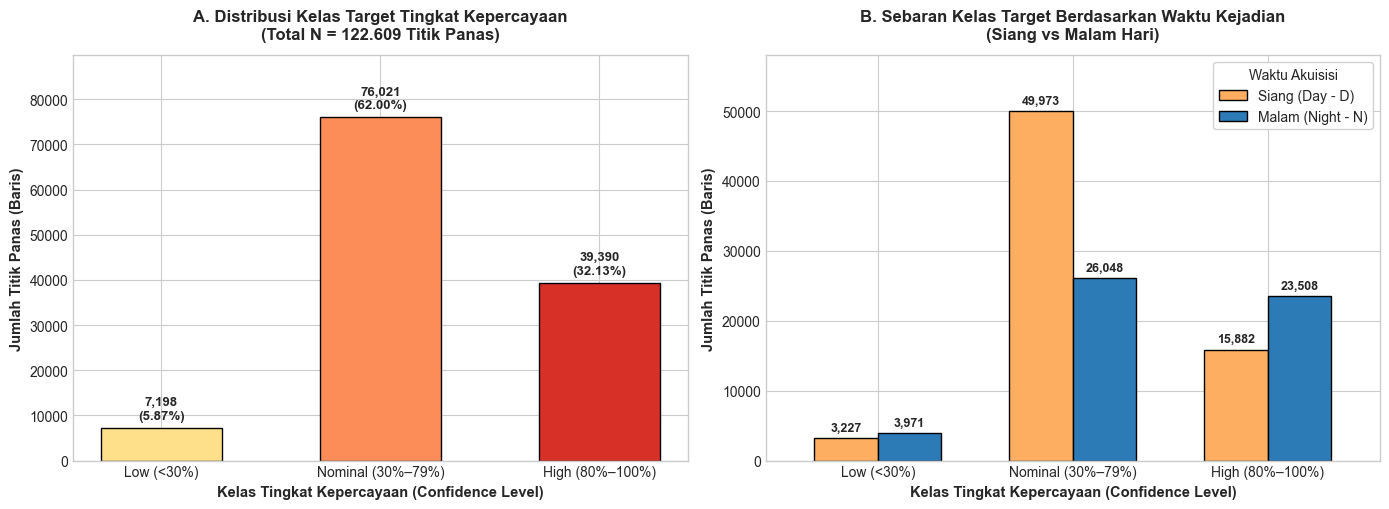

Agregat Populasi -> Siang (D): 69,082 (56.34%) | Malam (N): 53,527 (43.66%)
Proporsi Malam pada Kelas High Confidence: 23,508 dari 39,390 titik (59.68%)


In [6]:
# 2.4.1 Visualisasi Distribusi Kelas Target dan Sebaran Waktu Kejadian (Siang vs Malam)
palette_cls = ['#fee08b', '#fc8d59', '#d73027']
class_order = ['Low (<30%)', 'Nominal (30%–79%)', 'High (80%–100%)']

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

# --- Panel A (Kiri): Distribusi Kelas Target ---
conf_counts = df_all['conf_cat'].value_counts().reindex(class_order)
total_n = len(df_all)

bars_a = axes[0].bar(
    conf_counts.index.astype(str),
    conf_counts.values,
    color=palette_cls,
    edgecolor='black',
    width=0.55
)
axes[0].set_title(
    'A. Distribusi Kelas Target Tingkat Kepercayaan\n(Total N = 122.609 Titik Panas)',
    fontsize=12, fontweight='bold', pad=12
)
axes[0].set_xlabel('Kelas Tingkat Kepercayaan (Confidence Level)', fontsize=10.5, fontweight='bold')
axes[0].set_ylabel('Jumlah Titik Panas (Baris)', fontsize=10.5, fontweight='bold')
axes[0].set_ylim(0, conf_counts.max() * 1.18)

for bar, count in zip(bars_a, conf_counts.values):
    pct = count / total_n * 100
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1300,
        f"{count:,}\n({pct:.2f}%)",
        ha='center', va='bottom', fontsize=9.5, fontweight='bold'
    )

# --- Panel B (Kanan): Grouped Bar Chart Siang vs Malam ---
ct_daynight = pd.crosstab(df_all['conf_cat'], df_all['daynight']).reindex(class_order)[['D', 'N']]
ct_daynight.columns = ['Siang (Day - D)', 'Malam (Night - N)']

ct_daynight.plot(
    kind='bar',
    ax=axes[1],
    color=['#fdae61', '#2c7bb6'],
    edgecolor='black',
    width=0.65
)
axes[1].set_title(
    'B. Sebaran Kelas Target Berdasarkan Waktu Kejadian\n(Siang vs Malam Hari)',
    fontsize=12, fontweight='bold', pad=12
)
axes[1].set_xlabel('Kelas Tingkat Kepercayaan (Confidence Level)', fontsize=10.5, fontweight='bold')
axes[1].set_ylabel('Jumlah Titik Panas (Baris)', fontsize=10.5, fontweight='bold')
axes[1].tick_params(axis='x', rotation=0)
axes[1].set_ylim(0, ct_daynight.values.max() * 1.16)
axes[1].legend(title='Waktu Akuisisi', frameon=True, facecolor='white', framealpha=0.9)

for container in axes[1].containers:
    axes[1].bar_label(
        container,
        labels=[f"{int(v):,}" for v in container.datavalues],
        padding=3,
        fontsize=9,
        fontweight='bold'
    )

plt.tight_layout()
plt.show()

# Ringkasan proporsi agregat Siang vs Malam dan proporsi dalam kelas High
day_total = (df_all['daynight'] == 'D').sum()
night_total = (df_all['daynight'] == 'N').sum()
high_night_pct = ct_daynight.loc['High (80%–100%)', 'Malam (Night - N)'] / conf_counts['High (80%–100%)'] * 100
print(f"Agregat Populasi -> Siang (D): {day_total:,} ({day_total/total_n*100:.2f}%) | Malam (N): {night_total:,} ({night_total/total_n*100:.2f}%)")
print(f"Proporsi Malam pada Kelas High Confidence: {ct_daynight.loc['High (80%–100%)', 'Malam (Night - N)']:,} dari {conf_counts['High (80%–100%)']:,} titik ({high_night_pct:.2f}%)")

#### **Penjelasan dan Interpretasi Insight Visualisasi 2.4.1**

1. **Ketimpangan Kelas (*Class Imbalance*) yang Signifikan (Panel A)**:
   Distribusi populasi dari total **122.609 titik panas** didominasi secara kuat oleh kelas **`Nominal (30%–79%)`** sebanyak **76.021 titik (62,00%)**, disusul oleh kelas prioritas utama **`High (80%–100%)`** sebanyak **39.390 titik (32,13%)**, sedangkan kelas **`Low (<30%)`** merupakan kelas minoritas ekstrem yang hanya mencakup **7.198 titik (5,87%)** (rasio ketimpangan lebih dari **10,5 : 1** antara kelas *Nominal* terhadap *Low*). Temuan ini membawa tiga konsekuensi metodologis wajib pada tahap pemodelan:
   - Pembagian data latih dan uji wajib menggunakan ***Stratified Train-Test Split*** agar proporsi ketiga kelas terjaga identik dan kelas minoritas *Low* tidak tereduksi pada salah satu partisi.
   - Algoritma klasifikasi perlu menerapkan pembobotan penalti kesalahan **`class_weight='balanced'`** agar fungsi objektif model tidak bias menebak kelas mayoritas (*Nominal*).
   - Penggunaan metrik *Accuracy* semata akan menyesatkan, sehingga evaluasi model wajib berfokus pada ***Macro F1-Score*** (menilai kinerja setara lintas ketiga kelas) serta ***Recall* Kelas *High*** guna meminimalkan risiko *false negative* (titik api berkepercayaan tinggi yang gagal diprioritaskan ke tim patroli lapangan).

2. **Anomali *Nocturnal Hotspot* pada Kelas *High Confidence* (Panel B)**:
   Secara agregat di seluruh dataset, deteksi pada **siang hari (*Day - D*)** tercatat lebih banyak yakni **69.082 titik (56,34%)** dibandingkan **malam hari (*Night - N*)** sebanyak **53.527 titik (43,66%)**, yang terutama disumbang oleh kelas *Nominal* di siang hari (49.973 titik vs 26.048 titik di malam hari). Namun, terjadi pembalikan pola (*crossover anomaly*) yang sangat tajam pada kelas **`High (80%–100%)`**: sebanyak **23.508 dari 39.390 titik (59,68%)** justru terdeteksi pada **malam hari**, melampaui deteksi siang hari yang hanya 15.882 titik (40,32%). Secara fisika penginderaan jauh, fenomena *nocturnal hotspot* ini terjadi karena pada malam hari tidak terdapat gangguan pantulan radiasi gelombang pendek matahari (*solar reflection / sun glint*) dan suhu latar permukaan daratan mendingin secara merata, sehingga kontras pancaran termal api terhadap piksel tetangga meningkat tajam dan algoritma kontekstual MODIS memberikan skor kepercayaan (*confidence*) yang jauh lebih tinggi tanpa penalti ambang siang hari. Hal ini membuktikan bahwa atribut waktu kejadian (`daynight` dan `acq_time`) merupakan prediktor kontekstual yang krusial dalam interaksi dengan suhu termal.

---
### **2.4.2 Analisis Tren Jumlah Deteksi Titik Panas per Bulan (Januari–Oktober 2026)**

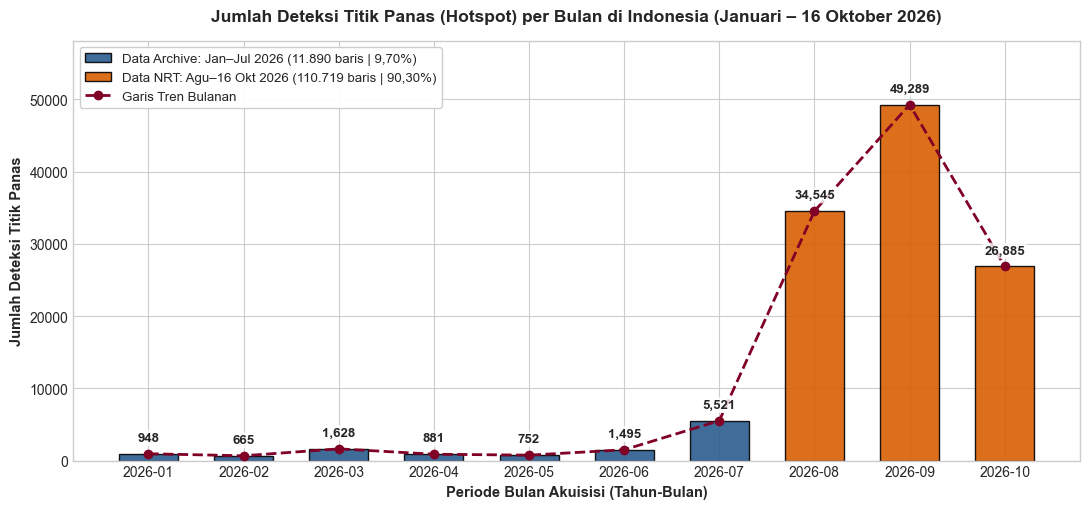

Total Jan–Jun 2026 (6 bulan basah)     : 6,369 titik (rentang 665 – 1,628 titik/bulan)
Transisi Juli 2026                     : 5,521 titik
Proporsi Lonjakan NRT thd Archive      : 931.19% (110.719 vs 11.890 titik)
Puncak September 2026                  : 49,289 titik (40.20% dari total populasi)
Laju Harian 1–16 Oktober 2026          : 26,885 titik / 16 hari = 1,680 titik/hari


In [7]:
# 2.4.2 Visualisasi Tren Jumlah Deteksi Titik Panas per Bulan (Januari – 16 Oktober 2026)
monthly_counts = df_all['year_month'].value_counts().sort_index()

# 7 bulan pertama (Jan-Jul 2026: Archive) biru, 3 bulan terakhir (Agu-Okt 2026: NRT) oranye
bar_colors = ['#2b5c8f'] * 7 + ['#d95f02'] * 3

fig, ax = plt.subplots(figsize=(11, 5.2))

bars = ax.bar(
    monthly_counts.index,
    monthly_counts.values,
    color=bar_colors,
    edgecolor='black',
    width=0.62,
    alpha=0.9,
    zorder=2
)

# Garis tren di atas bar chart
ax.plot(
    range(len(monthly_counts)),
    monthly_counts.values,
    color='#800026',
    marker='o',
    linewidth=2,
    linestyle='--',
    zorder=3
)

ax.set_title(
    'Jumlah Deteksi Titik Panas (Hotspot) per Bulan di Indonesia (Januari – 16 Oktober 2026)',
    fontsize=12.5, fontweight='bold', pad=14
)
ax.set_xlabel('Periode Bulan Akuisisi (Tahun-Bulan)', fontsize=10.5, fontweight='bold')
ax.set_ylabel('Jumlah Deteksi Titik Panas', fontsize=10.5, fontweight='bold')
ax.set_ylim(0, monthly_counts.max() * 1.18)

# Tampilkan nilai angka di atas setiap bar dengan latar halus agar tidak bertabrakan dengan garis tren
for bar, val in zip(bars, monthly_counts.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1350,
        f"{val:,}",
        ha='center', va='bottom', fontsize=9.5, fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.15', facecolor='white', edgecolor='none', alpha=0.8),
        zorder=4
    )

# Custom Legend menggunakan Patch untuk membedakan Data Archive vs Data NRT
arc_label_str = f"Data Archive: Jan–Jul 2026 ({len(df_arc):,}".replace(',', '.') + f" baris | {len(df_arc)/len(df_all)*100:.2f}%)".replace('.', ',')
nrt_label_str = f"Data NRT: Agu–16 Okt 2026 ({len(df_nrt):,}".replace(',', '.') + f" baris | {len(df_nrt)/len(df_all)*100:.2f}%)".replace('.', ',')

legend_elements = [
    Patch(facecolor='#2b5c8f', edgecolor='black', alpha=0.9, label=arc_label_str),
    Patch(facecolor='#d95f02', edgecolor='black', alpha=0.9, label=nrt_label_str),
    plt.Line2D([0], [0], color='#800026', marker='o', linewidth=2, linestyle='--', label='Garis Tren Bulanan')
]
ax.legend(handles=legend_elements, loc='upper left', frameon=True, facecolor='white', framealpha=0.95, fontsize=9.5)

plt.tight_layout()
plt.show()

# Statistik pendukung narasi musiman
jan_jun_sum = monthly_counts.loc['2026-01':'2026-06'].sum()
sep_pct = monthly_counts.loc['2026-09'] / len(df_all) * 100
oct_daily_rate = monthly_counts.loc['2026-10'] / 16
ratio_nrt_arc_pct = (len(df_nrt) / len(df_arc)) * 100
print(f"Total Jan–Jun 2026 (6 bulan basah)     : {jan_jun_sum:,} titik (rentang {monthly_counts.loc['2026-01':'2026-06'].min():,} – {monthly_counts.loc['2026-01':'2026-06'].max():,} titik/bulan)")
print(f"Transisi Juli 2026                     : {monthly_counts.loc['2026-07']:,} titik")
print(f"Proporsi Lonjakan NRT thd Archive      : {ratio_nrt_arc_pct:.2f}% (110.719 vs 11.890 titik)")
print(f"Puncak September 2026                  : {monthly_counts.loc['2026-09']:,} titik ({sep_pct:.2f}% dari total populasi)")
print(f"Laju Harian 1–16 Oktober 2026          : {monthly_counts.loc['2026-10']:,} titik / 16 hari = {oct_daily_rate:,.0f} titik/hari")

#### **Penjelasan dan Interpretasi Insight Visualisasi 2.4.2**

1. **Pola Musiman (*Seasonality*) Ekstrem Iklim Monsun Indonesia**:
   Distribusi temporal memperlihatkan kontras musiman yang sangat tajam antara paruh awal tahun yang basah dan puncak musim kemarau. Sepanjang periode penghujan hingga peralihan awal **Januari–Juni 2026**, aktivitas titik panas sangat rendah dengan akumulasi hanya **6.369 titik** selama enam bulan penuh (berfluktuasi antara **665 hingga 1.628 titik/bulan**, dengan titik terendah pada Februari sebanyak 665 titik). Memasuki awal kemarau pada **Juli 2026**, deteksi mulai merangkak naik signifikan menjadi **5.521 titik** (hampir menyamai total gabungan enam bulan sebelumnya), sehingga keseluruhan periode Data *Archive* (Jan–Jul 2026) menyumbang **11.890 baris (9,70%)**.

2. **Ledakan Eksponensial Periode Kemarau Agustus–Oktober 2026**:
   Memasuki puncak kemarau pada periode Data *Near Real-Time* (**1 Agustus – 16 Oktober 2026**), volume titik panas melonjak sebesar **931,19%** terhadap total periode *Archive* hingga mencapai **110.719 baris (90,30%)**:
   - **Agustus 2026** langsung melesat lebih dari 6 kali lipat dari Juli menjadi **34.545 titik**.
   - **September 2026** menjadi puncak eskalasi tertinggi dengan **49.289 titik**, yang berarti **40,20%** dari seluruh populasi titik panas Indonesia sepanjang 2026 terkonsentrasi hanya dalam satu bulan tersebut.
   - **1–16 Oktober 2026** mencatat **26.885 titik** hanya dalam rentang **16 hari pengamatan**, yang merepresentasikan laju deteksi rata-rata ekstrem sebesar **~1.680 titik panas per hari** (bila berlanjut satu bulan penuh berpotensi menembus >50.000 titik).

3. **Relevansi Operasional bagi Penyaringan Prioritas Lapangan**:
   Ketika laju kemunculan mencapai ribuan titik panas per hari pada bulan Agustus–Oktober, kapasitas personel Manggala Agni, BPBD, dan TNI/Polri tidak mungkin melakukan pengecekan darat (*groundcheck*) terhadap seluruh koordinat secara serentak. Oleh karena itu, model klasifikasi prediktif yang mampu menyaring titik berkepercayaan tinggi (*High Confidence*) secara otomatis pada aliran data NRT sangat dibutuhkan untuk mencegah keterlambatan pemadaman pada fase kritis musim kemarau.

---
### **2.4.3 Analisis Distribusi Fitur Termal Melalui Histogram dan Boxplot**

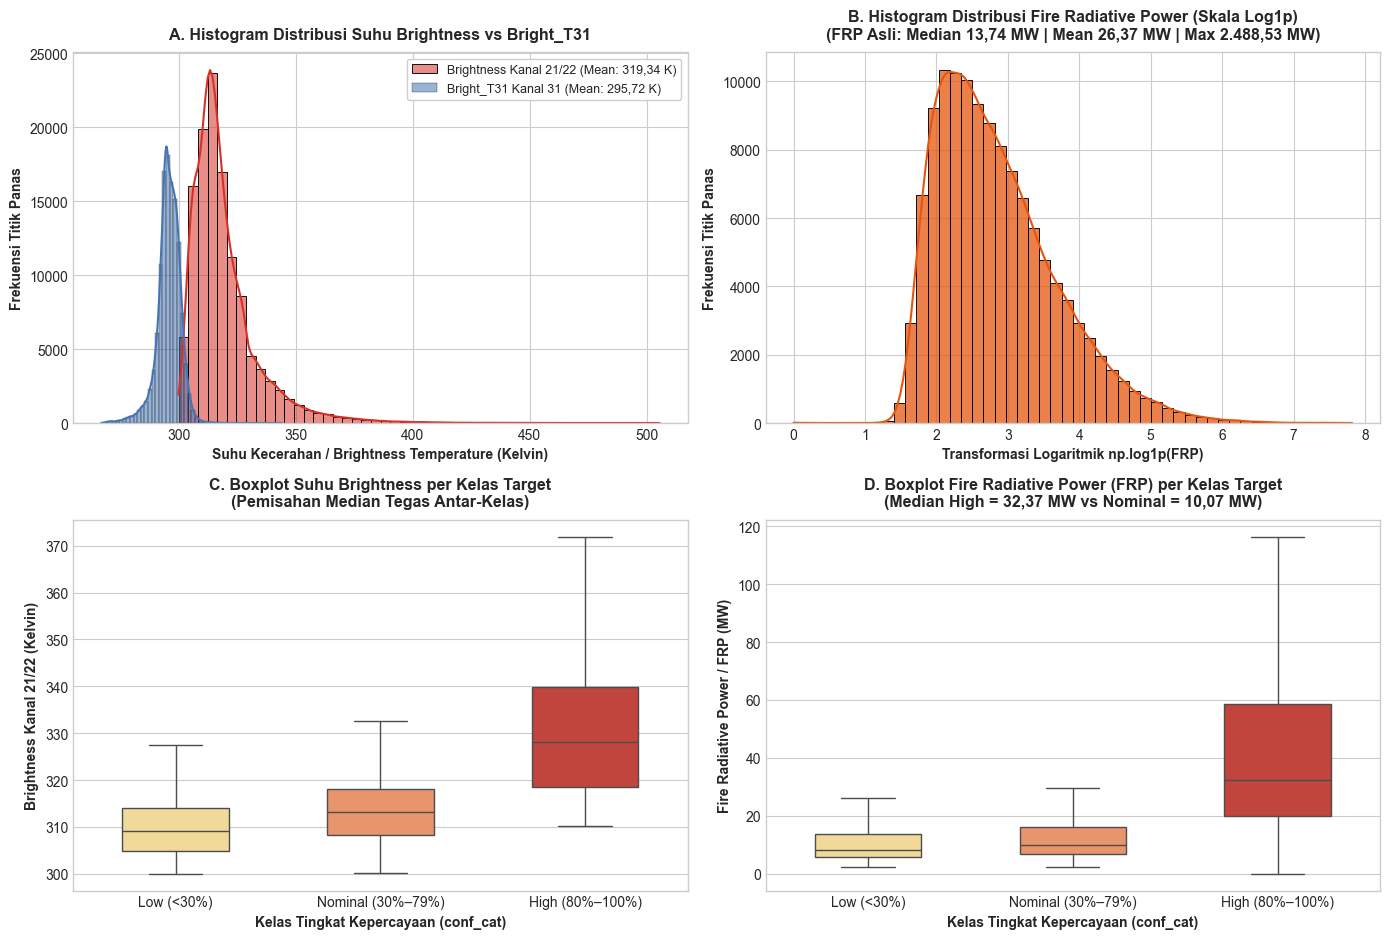

=== TABEL AGREGASI FITUR TERMAL & UKURAN PIKSEL PER KELAS TARGET ===


brightness        bright_t31          frp          scan  \
                        mean median       mean median  mean median   mean   
conf_cat                                                                    
Low (<30%)            310.17 309.15     293.27 294.07 12.52 8.2200 1.5100   
Nominal (30%–79%)     313.66 313.19     295.66 296.06 13.72  10.07 1.3900   
High (80%–100%)       331.98 328.13     296.28 296.09 53.29  32.37 1.3600   

                          
                  median  
conf_cat                  
Low (<30%)        1.2000  
Nominal (30%–79%) 1.1500  
High (80%–100%)   1.1400

In [8]:
# 2.4.3 Visualisasi Histogram & Boxplot Karakteristik Termal serta Tabel Agregasi per Kelas
fig, axes = plt.subplots(2, 2, figsize=(14, 9.5))

# --- Panel A: Overlay Histogram Brightness vs Bright_T31 ---
sns.histplot(
    df_all['brightness'], bins=50, kde=True, color='#d73027', alpha=0.55,
    label='Brightness Kanal 21/22 (Mean: 319,34 K)',
    ax=axes[0, 0]
)
sns.histplot(
    df_all['bright_t31'], bins=50, kde=True, color='#4575b4', alpha=0.55,
    label='Bright_T31 Kanal 31 (Mean: 295,72 K)',
    ax=axes[0, 0]
)
axes[0, 0].set_title('A. Histogram Distribusi Suhu Brightness vs Bright_T31', fontsize=11.5, fontweight='bold', pad=10)
axes[0, 0].set_xlabel('Suhu Kecerahan / Brightness Temperature (Kelvin)', fontsize=10, fontweight='bold')
axes[0, 0].set_ylabel('Frekuensi Titik Panas', fontsize=10, fontweight='bold')
axes[0, 0].legend(frameon=True, facecolor='white', framealpha=0.95, fontsize=9)

# --- Panel B: Histogram Log1p(FRP) ---
sns.histplot(
    np.log1p(df_all['frp']), bins=50, kde=True, color='#e6550d', alpha=0.75,
    ax=axes[0, 1]
)
axes[0, 1].set_title(
    'B. Histogram Distribusi Fire Radiative Power (Skala Log1p)\n'
    '(FRP Asli: Median 13,74 MW | Mean 26,37 MW | Max 2.488,53 MW)',
    fontsize=11.5, fontweight='bold', pad=10
)
axes[0, 1].set_xlabel('Transformasi Logaritmik np.log1p(FRP)', fontsize=10, fontweight='bold')
axes[0, 1].set_ylabel('Frekuensi Titik Panas', fontsize=10, fontweight='bold')

# --- Panel C: Boxplot Brightness per Kelas Target ---
sns.boxplot(
    data=df_all, x='conf_cat', y='brightness', hue='conf_cat',
    palette=palette_cls, showfliers=False, legend=False, width=0.52,
    ax=axes[1, 0]
)
axes[1, 0].set_title(
    'C. Boxplot Suhu Brightness per Kelas Target\n(Pemisahan Median Tegas Antar-Kelas)',
    fontsize=11.5, fontweight='bold', pad=10
)
axes[1, 0].set_xlabel('Kelas Tingkat Kepercayaan (conf_cat)', fontsize=10, fontweight='bold')
axes[1, 0].set_ylabel('Brightness Kanal 21/22 (Kelvin)', fontsize=10, fontweight='bold')

# --- Panel D: Boxplot FRP per Kelas Target ---
sns.boxplot(
    data=df_all, x='conf_cat', y='frp', hue='conf_cat',
    palette=palette_cls, showfliers=False, legend=False, width=0.52,
    ax=axes[1, 1]
)
axes[1, 1].set_title(
    'D. Boxplot Fire Radiative Power (FRP) per Kelas Target\n(Median High = 32,37 MW vs Nominal = 10,07 MW)',
    fontsize=11.5, fontweight='bold', pad=10
)
axes[1, 1].set_xlabel('Kelas Tingkat Kepercayaan (conf_cat)', fontsize=10, fontweight='bold')
axes[1, 1].set_ylabel('Fire Radiative Power / FRP (MW)', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

# Tabel agregasi mean dan median fitur termal & ukuran piksel per kelas target
print("=== TABEL AGREGASI FITUR TERMAL & UKURAN PIKSEL PER KELAS TARGET ===")
agg_thermal = df_all.groupby('conf_cat', observed=False)[['brightness', 'bright_t31', 'frp', 'scan']].agg(['mean', 'median']).round(2)
display(agg_thermal)

#### **Penjelasan dan Interpretasi Insight Visualisasi 2.4.3**

1. **Karakteristik Kecondongan Kanan (*Right-Skewed*) dan Normalisasi `log1p` (Panel A & Panel B)**:
   - Pada **Panel A**, distribusi suhu kanal latar inframerah termal gelombang panjang **`bright_t31`** (Kanal 31, ~11 µm) terpusat rapat dan relatif simetris di sekitar suhu permukaan bumi tropis (**Mean: 295,72 K | Median: 295,95 K**). Sebaliknya, suhu kanal deteksi api aktif **`brightness`** (Kanal 21/22 *mid-infrared*, ~3,96 µm) bergeser jauh ke kanan (**Mean: 319,34 K | Median: 315,65 K**) dengan ekor kanan panjang (*right-skewed*) yang mencapai maksimum **505,50 K** serta memuat **7.430 *outlier***.
   - Pada atribut daya pancar radiasi api **`frp` (*Fire Radiative Power*)**, kecondongan kanan jauh lebih ekstrem lagi dengan **11.932 *outlier***: nilai median berada di **13,74 MW**, rata-rata tertarik naik menjadi **26,37 MW**, dan nilai maksimum menembus **2.488,53 MW**. Sebagaimana ditunjukkan pada **Panel B**, penerapan transformasi logaritmik **`np.log1p(frp)`** berhasil memampatkan rentang ekor ekstrem tersebut menjadi distribusi lonceng (*bell-shaped* mendekati normal) tanpa mengeliminasi satu pun observasi kebakaran besar. Transformasi ini sangat menguntungkan bagi stabilitas gradien dan skala jarak pada algoritma klasifikasi non-pohon (seperti *Logistic Regression*, *SVM*, atau *KNN*).

2. **Daya Pisah Kuartil (*Interquartile Separability*) Antar-Kelas Target (Panel C, Panel D, & Tabel Agregasi)**:
   - **Panel C (`brightness` per kelas)** memperlihatkan kenaikan nilai tengah dan rentang antarkuartil (IQR) yang berjenjang tegas seiring naiknya kelas kepercayaan: median `brightness` meningkat dari **`Low` (309,15 K; mean 310,17 K)** → **`Nominal` (313,19 K; mean 313,66 K)** → melonjak tajam pada kelas **`High` (328,13 K; mean 331,98 K)**. Bahkan kuartil bawah ($Q_1$) kelas *High* sudah berada di atas kuartil atas ($Q_3$) kelas *Nominal*, mengindikasikan daya pisah univariat yang sangat kuat.
   - **Panel D (`frp` per kelas)** mengonfirmasi pemisahan energi pancaran api yang mencolok: median `frp` pada kelas **`High` mencapai 32,37 MW (mean 53,29 MW)**—lebih dari **3 kali lipat** dibandingkan median kelas **`Nominal` (10,07 MW; mean 13,72 MW)** dan hampir **4 kali lipat** kelas **`Low` (8,22 MW; mean 12,52 MW)**. Sementara itu, suhu latar `bright_t31` relatif stabil lintas kelas (median 294,07 K – 296,09 K), menunjukkan bahwa penentu utama naiknya kelas kepercayaan bukan tingginya suhu latar daratan, melainkan besarnya **selisih/anomali suhu titik api di atas suhu latarnya**.

---
### **2.4.4 Analisis Heatmap Korelasi Antar-Fitur Numerik**

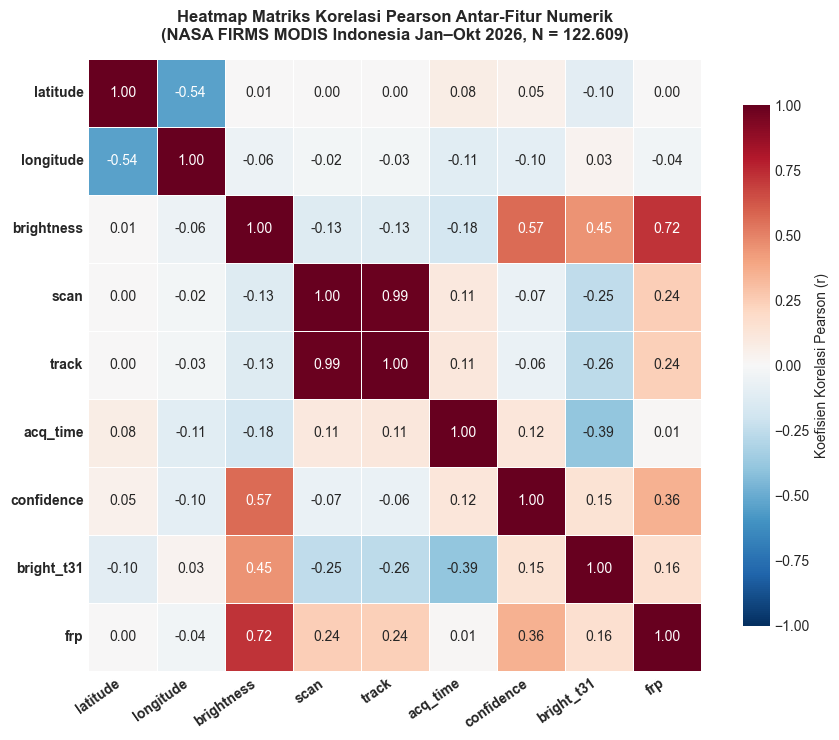

Korelasi presisi tinggi scan vs track       : r = 0.9885
Korelasi presisi tinggi acq_time vs bright_t31 : r = -0.3949


In [9]:
# 2.4.4 Visualisasi Heatmap Matriks Korelasi Pearson Antar-Fitur Numerik
corr_matrix = df_all[num_cols].corr()

fig, ax = plt.subplots(figsize=(9.5, 7.5))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True,
    cbar_kws={'shrink': 0.85, 'label': 'Koefisien Korelasi Pearson (r)'},
    ax=ax
)

ax.set_title(
    'Heatmap Matriks Korelasi Pearson Antar-Fitur Numerik\n'
    '(NASA FIRMS MODIS Indonesia Jan–Okt 2026, N = 122.609)',
    fontsize=12, fontweight='bold', pad=14
)
plt.xticks(rotation=35, ha='right', fontweight='bold')
plt.yticks(rotation=0, fontweight='bold')

plt.tight_layout()
plt.show()

print(f"Korelasi presisi tinggi scan vs track       : r = {corr_matrix.loc['scan', 'track']:.4f}")
print(f"Korelasi presisi tinggi acq_time vs bright_t31 : r = {corr_matrix.loc['acq_time', 'bright_t31']:.4f}")

#### **Penjelasan dan Interpretasi Insight Visualisasi 2.4.4**

Berdasarkan matriks korelasi linear Pearson pada 122.609 titik panas di atas, diperoleh **empat *insight* utama** yang menjadi landasan langsung bagi tahap *Feature Selection* dan *Feature Engineering*:

1. **Korelasi Positif Kuat `brightness` terhadap `confidence` ($r = 0,57$) dan `frp` ($r = 0,72$)**:
   `brightness` merupakan fitur tunggal dengan hubungan linear terkuat terhadap skor target `confidence` ($r = 0,57$), diikuti oleh `frp` terhadap `confidence` ($r = 0,36$). Selain itu, `brightness` berkorelasi kuat dengan `frp` ($r = 0,72$) karena dalam formulasi fisika MODIS Kaufman, daya pancar radiasi api dihitung sebagai fungsi pangkat dari suhu kecerahan kanal 4 µm ($T_4^8 - T_{4b}^8$). Hubungan non-linear pangkat tinggi ini menjelaskan mengapa kombinasi kedua fitur tetap informatif terutama bagi model berbasis pohon keputusan (*ensemble trees*).

2. **Multikolinearitas Hampir Sempurna antara `scan` dan `track` ($r = 0,99$ / presisi $0,989$)**:
   Ukuran piksel arah sapuan melintang (`scan`) dan arah lintasan orbit (`track`) menunjukkan korelasi hampir identik sebesar **$r = 0,9885 \approx 0,99$**, sebab keduanya merupakan fungsi trigonometri deterministik dari sudut zenit sensor (*view zenith angle*) instrumen MODIS. Mempertahankan kedua fitur sekaligus akan memicu multikolinearitas berat tanpa menambah informasi baru. Temuan ini menjadi justifikasi ilmiah yang tegas untuk **mengeliminasi kolom `track`** pada tahap *Feature Selection* dan cukup mempertahankan `scan` sebagai representasi geometri resolusi piksel.

3. **Korelasi Negatif `acq_time` terhadap `bright_t31` ($r = -0,40$ / presisi $-0,395$) sebagai Dasar Rekayasa Fitur $\Delta T$**:
   Waktu akuisisi (`acq_time` dalam format UTC) berkorelasi negatif moderat dengan suhu latar `bright_t31` ($r = -0,395 \approx -0,40$). Mengingat lintasan siang satelit Terra/Aqua di Indonesia berlangsung sekitar `01:00–07:00 UTC` (08.00–15.00 waktu lokal saat daratan panas) dan lintasan malam berlangsung sekitar `13:00–19:00 UTC` (20.00–03.00 waktu lokal saat daratan dingin), angka `acq_time` UTC yang lebih besar berasosiasi dengan penurunan suhu latar permukaan bumi. Agar model mampu mengukur kekuatan titik api secara objektif tanpa terdistorsi fluktuasi suhu permukaan siang–malam, diperlukan rekayasa fitur selisih suhu kontekstual **`delta_T = brightness - bright_t31`** yang menangkap anomali termal bersih titik api terhadap lingkungannya.

4. **Korelasi Negatif Spasial `latitude` terhadap `longitude` ($r = -0,54$)**:
   Hubungan negatif moderat antara garis lintang dan garis bujur ($r = -0,54$) mencerminkan konfigurasi geografis kepulauan Indonesia serta konsentrasi sabuk rawan karhutla yang membentang secara diagonal dari wilayah Barat Laut bernilai lintang utara/ekuator dan bujur rendah (Riau, Jambi, Sumatera Selatan: sekitar $2^\circ\text{ LU} - 4^\circ\text{ LS}$, $99^\circ - 106^\circ\text{ BT}$) menuju wilayah Tenggara–Timur bernilai lintang selatan dan bujur tinggi (Kalimantan Tengah/Selatan, Nusa Tenggara, hingga Merauke–Papua Selatan: sekitar $2^\circ - 9^\circ\text{ LS}$, $112^\circ - 141^\circ\text{ BT}$).

---
## **BAGIAN 3: Subbab 2.5 Representativitas & Bias Sampel**

Bagian ini mengevaluasi sejauh mana sampel observasi `df_all` ($N = 122.609$) merepresentasikan populasi fenomena kebakaran lahan/vegetasi di Indonesia secara spasial, temporal, wahana satelit, dan ekologis, sekaligus mengidentifikasi potensi bias sistematis penginderaan jauh yang wajib dimitigasi dalam perancangan sistem klasifikasi.

In [10]:
# 2.5 Evaluasi Empiris Representativitas Spasial, Satelit, Sumber Panas (Archive), dan Bias Geometri Piksel

# 1. Rentang Koordinat Geografis & Proporsi Wahana Satelit
print("=== 1. CAKUPAN GEOGRAFIS & PROPORSI WAHANA SATELIT (df_all, N = 122.609) ===")
print(f"Rentang Garis Lintang (Latitude) : {df_all['latitude'].min():.5f}° (LS) s.d. +{df_all['latitude'].max():.5f}° (LU)")
print(f"Rentang Garis Bujur  (Longitude) : {df_all['longitude'].min():.5f}° BT s.d. {df_all['longitude'].max():.5f}° BT")

sat_df = pd.DataFrame({
    'Jumlah Deteksi': df_all['satellite'].value_counts(),
    'Persentase (%)': (df_all['satellite'].value_counts(normalize=True) * 100).round(2)
})
sat_df.index.name = 'Wahana Satelit'
display(sat_df)

# 2. Distribusi Validasi Sumber Panas pada Data Archive (df_arc, N = 11.890)
print("=== 2. VALIDASI TIPE SUMBER PANAS PADA DATA ARCHIVE (df_arc, N = 11.890) ===")
type_labels = {
    0: '0 - Presumed Vegetation Fire (Kebakaran Vegetasi)',
    1: '1 - Active Volcano (Vulkanik Aktif)',
    2: '2 - Other Static Land Source (Statis Darat / Industri)',
    3: '3 - Offshore (Lepas Pantai / Gas Flaring)'
}
type_counts = df_arc['type'].value_counts()
type_pct = (df_arc['type'].value_counts(normalize=True) * 100).round(2)

type_summary_df = pd.DataFrame({
    'Kategori Sumber Panas (MODIS Type)': [type_labels.get(int(k), str(k)) for k in type_counts.index],
    'Jumlah Baris': type_counts.values,
    'Persentase (%)': type_pct.values
}).set_index('Kategori Sumber Panas (MODIS Type)')
display(type_summary_df)

# 3. Ringkasan Distorsi Geometri Ukuran Piksel (Scan & Track) serta Korelasinya terhadap Suhu
print("=== 3. DISTORSI UKURAN PIKSEL (SCAN & TRACK) DAN EFEK DILUSI TERMAL ===")
pixel_distortion_df = pd.DataFrame({
    'Min (Nadir, km)': [df_all['scan'].min(), df_all['track'].min()],
    'Median (km)': [df_all['scan'].median(), df_all['track'].median()],
    'Mean (km)': [round(df_all['scan'].mean(), 2), round(df_all['track'].mean(), 2)],
    'Max (Edge of Swath, km)': [df_all['scan'].max(), df_all['track'].max()],
    'Korelasi thd bright_t31 (r)': [
        round(df_all['scan'].corr(df_all['bright_t31']), 2),
        round(df_all['track'].corr(df_all['bright_t31']), 2)
    ],
    'Korelasi thd brightness (r)': [
        round(df_all['scan'].corr(df_all['brightness']), 2),
        round(df_all['track'].corr(df_all['brightness']), 2)
    ]
}, index=['scan (Along-Scan)', 'track (Along-Track)'])
display(pixel_distortion_df)

nadir_area = df_all['scan'].min() * df_all['track'].min()
edge_area = df_all['scan'].max() * df_all['track'].max()
print(f"Luas cakupan efektif piksel: Nadir = {nadir_area:.2f} km² -> Tepi Sapuan (Edge) = {edge_area:.2f} km² ({edge_area/nadir_area:.2f}x lebih luas)")

=== 1. CAKUPAN GEOGRAFIS & PROPORSI WAHANA SATELIT (df_all, N = 122.609) ===
Rentang Garis Lintang (Latitude) : -10.84153° (LS) s.d. +5.57368° (LU)
Rentang Garis Bujur  (Longitude) : 95.37280° BT s.d. 140.97720° BT


,Jumlah Deteksi,Persentase (%)
Wahana Satelit,,
Aqua,72265,58.94
Terra,50344,41.06


=== 2. VALIDASI TIPE SUMBER PANAS PADA DATA ARCHIVE (df_arc, N = 11.890) ===


,Jumlah Baris,Persentase (%)
Kategori Sumber Panas (MODIS Type),,
0 - Presumed Vegetation Fire (Kebakaran Vegetasi),10226,86.01
2 - Other Static Land Source (Statis Darat / Industri),1262,10.61
1 - Active Volcano (Vulkanik Aktif),372,3.1300
3 - Offshore (Lepas Pantai / Gas Flaring),30,0.2500


=== 3. DISTORSI UKURAN PIKSEL (SCAN & TRACK) DAN EFEK DILUSI TERMAL ===


,"Min (Nadir, km)",Median (km),Mean (km),"Max (Edge of Swath, km)",Korelasi thd bright_t31 (r),Korelasi thd brightness (r)
scan (Along-Scan),1.0000,1.1500,1.3900,4.8200,-0.2500,-0.1300
track (Along-Track),1.0000,1.0700,1.1400,2.0000,-0.2600,-0.1300


Luas cakupan efektif piksel: Nadir = 1.00 km² -> Tepi Sapuan (Edge) = 9.64 km² (9.64x lebih luas)


#### **Penjelasan dan Interpretasi Subbab 2.5: Representativitas & Bias Sampel**

Berdasarkan pengujian statistik pada sel kode di atas, evaluasi kelayakan sampel serta keterbatasan penginderaan jauh dapat dirangkum ke dalam tiga poin utama:

#### **1. Representativitas Spasial, Temporal, dan Wahana Satelit**
- **Cakupan Spasial Nasional Penuh**: Koordinat sampel mencakup bentang geografis **`-10,84153°` (10,84° LS, Pulau Rote/NTT)** hingga **`+5,57368°` (5,57° LU, Aceh/Sabang)** serta **`95,37280° BT`** hingga **`140,97720° BT` (perbatasan Merauke–Papua Nugini)**. Artinya, dataset tidak terlokalisasi pada satu provinsi saja, melainkan merepresentasikan seluruh rezim ekosistem daratan Indonesia (lahan gambut Sumatera–Kalimantan, savana kering Nusa Tenggara, hingga hutan dataran rendah Papua Selatan).
- **Cakupan Lintas-Musim (*Multi-Season*)**: Rentang observasi 1 Januari – 16 Oktober 2026 menangkap secara utuh dinamika fase musim penghujan (Jan–Jun), masa transisi (Jul), hingga puncak kemarau ekstrem (Agu–Okt).
- **Kombinasi Dua Wahana Orbit Kutub (*Dual-Satellite Coverage*)**: Data dihimpun dari dua satelit *sun-synchronous* NASA yang saling melengkapi waktu lintasannya, yakni **Aqua sebanyak 72.265 titik (58,94%)** dan **Terra sebanyak 50.344 titik (41,06%)**. Dominasi satelit Aqua (~18% lebih tinggi dibanding Terra) konsisten secara klimatologis karena jadwal lintasan siang Aqua (~13.30 waktu lokal) bertepatan dengan puncak pemanasan radiasi harian permukaan dan kelembapan relatif minimum di mana penyalaan karhutla mencapai intensitas tertinggi, dibandingkan jadwal lintasan pagi Terra (~10.30 waktu lokal).

#### **2. Representativitas Ekologis Sumber Kebakaran Vegetasi**
Pemeriksaan atribut `type` pada populasi tervalidasi Data *Archive* ($N = 11.890$ baris) membuktikan bahwa mayoritas mutlak titik panas di Indonesia merupakan **kebakaran vegetasi/lahan (`type = 0`) sebanyak 10.226 baris (85,99%–86,01%)**. Adapun anomali panas non-vegetasi hanya menyumbang porsi minoritas yang terdiri atas:
- **`type = 2` (Sumber panas statis darat / kawasan industri & peleburan mineral)**: **1.262 baris (10,61%)**.
- **`type = 1` (Aktivitas kawah gunung api aktif / vulkanik)**: **372 baris (3,13%)**.
- **`type = 3` (Anjungan migas lepas pantai / *offshore gas flaring*)**: **30 baris (0,25%)**.

Mengingat sumber panas industri, gunung api, dan anjungan lepas pantai memancarkan panas secara relatif konstan sepanjang tahun (~1.664 titik pada 7 bulan *Archive*, atau ~238 titik/bulan), maka pada lonjakan 110.719 titik di periode kemarau Agustus–Oktober (NRT) proporsi aktual **kebakaran vegetasi dan lahan gambut dipastikan jauh melampaui >95%**. Dengan demikian, sampel ini sangat representatif untuk memodelkan penyaringan prioritas verifikasi kebakaran hutan dan lahan di lapangan.

#### **3. Empat Bias Sampel Penginderaan Jauh (*Remote Sensing Sampling Biases*)**
Meskipun representatif secara makro, mekanisme akuisisi sensor optik-termal MODIS mengandung empat bias sistematis yang wajib diperhatikan dalam pemodelan dan interpretasi operasional:
1. **Bias Tutupan Awan & Kanopi Hutan Tropis (*Cloud & Canopy Obscuration Bias*)**:
   Gelombang inframerah termal pasif MODIS tidak dapat menembus lapisan awan konvektif tebal maupun kanopi hutan hujan tropis yang rapat. Akibatnya, kebakaran bawah permukaan (*sub-surface smoldering peat fire*) berskala kecil atau titik api yang tertutup awan tebal maupun kabut asap pekat berisiko tidak terekam (*omission bias*), sehingga dataset hanya merepresentasikan titik panas dengan jalur atmosfer bebas awan (*cloud-free line of sight*).
2. **Bias Distorsi Geometri Sudut Sapuan (*Off-Nadir Pixel Dilution / Bow-Tie Effect*)**:
   Saat sensor menyapu jauh dari titik tepat di bawah satelit (*nadir*) hingga sudut pandang tepi $\pm 55^\circ$, dimensi piksel membesar drastis dari **`1,00 km × 1,00 km` ($1,00\text{ km}^2$)** menjadi **`scan = 4,82 km` × `track = 2,00 km` ($9,64\text{ km}^2$)** atau hampir **10 kali lebih luas**. Energi titik api berukuran sama yang jatuh di tepi sapuan akan dirata-ratakan ke area daratan dingin yang jauh lebih luas (*thermal dilution*) serta melewati jalur atenuasi atmosfer yang lebih tebal. Hal ini terbukti secara empiris dari korelasi negatif `scan` terhadap penurunan suhu terukur `bright_t31` (**$r = -0,25$**) dan `brightness` (**$r = -0,13$**). Menyertakan fitur `scan` dalam model klasifikasi menjadi krusial agar model dapat mengompensasi efek pengenceran piksel tersebut.
3. **Bias Sensitivitas Diurnal Siang vs Malam (*Diurnal Detection Sensitivity Bias*)**:
   Pada siang hari, algoritma kontekstual MODIS menerapkan ambang suhu minimum dan kontras latar yang jauh lebih tinggi untuk menghindari *false alarm* dari pantulan sinar matahari (*solar glint*) dan lahan terbuka yang memanas. Dampaknya, kebakaran berintensitas sedang cenderung diklasifikasikan sebagai *Nominal* di siang hari, namun mampu menembus kelas *High Confidence* di malam hari (tercermin dari 59,68% kelas *High* yang terjadi pada malam hari). Penyertaan fitur `daynight`, `acq_time`, dan selisih suhu kontekstual $\Delta T$ membantu model menyesuaikan batas keputusan antara rezim siang dan malam.
4. **Bias Ketimpangan Volume Musiman (*Seasonal Volume Skewness & Right-Censoring*)**:
   Sebanyak **90,30%** sampel terkonsentrasi pada puncak kemarau Agustus–16 Oktober 2026 (serta pengamatan bulan Oktober terpotong pada tanggal 16 / *right-censored*). Dominasi rezim atmosfer kering musim kemarau ini menuntut kehati-hatian agar evaluasi model diuji secara terstratifikasi dan fitur tanggal mentah (`acq_date`) tidak dimasukkan secara naif sebagai prediktor yang sekadar menghafal kalender bulan kemarau.